# Group 05 — NLI preprocessing
Hamdi · UCLM Machine Learning · 2026/2027

Team, this is the data prep we can use for both blocks. Use `split_manifest.csv` for your experiments so we all score our models on the same examples.

## Run this first
In Colab, open the notebook and run all cells. Upload `contradictory-my-dear-watson.zip` when asked. Locally, put the ZIP in the working directory. In Kaggle, attach the competition dataset.

Sections 1–7 run with the default settings. The optional Block 1 cells start after the exports.

In [1]:
from pathlib import Path
import io, json, re, unicodedata, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import GroupShuffleSplit

SEED = 42
VALIDATION_FRACTION = 0.20
RUN_BLOCK1_BASELINES = False  # Switch on when you want to compare the two baselines.
MAKE_SUBMISSION_IF_BASELINES = False  # Enable when we have a model to submit.
MAX_CHAR_FEATURES = 35_000

np.random.seed(SEED)
IS_KAGGLE = Path('/kaggle/input').exists()
OUTPUT_DIR = Path('/kaggle/working') if IS_KAGGLE else Path.cwd() / 'nli_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
LABEL_NAMES = {0:'entailment', 1:'neutral', 2:'contradiction'}
print(f'Environment: {"Kaggle" if IS_KAGGLE else "Colab/local"}')
print('Output directory:', OUTPUT_DIR)
print('pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)

Environment: Colab/local
Output directory: /workspace/scratch/3752cb880e55/nli_outputs
pandas: 2.2.3 | scikit-learn: 1.8.0


## 1. Load the competition files
The ZIP has the labeled training pairs, the unlabeled test pairs, and the submission template.

In [2]:
def load_official_data():
    if IS_KAGGLE:
        candidates = [Path('/kaggle/input/contradictory-my-dear-watson')]
        candidates.extend(p.parent for p in sorted(Path('/kaggle/input').rglob('train.csv')))
        for folder in candidates:
            if all((folder / f).exists() for f in ['train.csv','test.csv','sample_submission.csv']):
                print('Kaggle input:', folder)
                return tuple(pd.read_csv(folder / f) for f in ['train.csv','test.csv','sample_submission.csv'])
    candidates = [Path.cwd() / 'contradictory-my-dear-watson.zip',
                  Path('/content/contradictory-my-dear-watson.zip'),
                  Path('/mnt/data/contradictory-my-dear-watson.zip')]
    found = next((p for p in candidates if p.is_file()), None)
    if found is None:
        try:
            from google.colab import files
            print('Please upload the original contradictory-my-dear-watson.zip file:')
            uploaded = files.upload()
            found = next((Path(k) for k in uploaded if k.endswith('.zip')), None)
        except ImportError:
            pass
    if found is None:
        raise FileNotFoundError('Official Kaggle ZIP missing. Upload contradictory-my-dear-watson.zip.')
    with zipfile.ZipFile(found) as z:
        needed = ['train.csv','test.csv','sample_submission.csv']
        assert set(needed).issubset(set(z.namelist())), f'Missing CSV in ZIP: {z.namelist()}'
        data = tuple(pd.read_csv(io.BytesIO(z.read(name))) for name in needed)
    print('ZIP used:', found)
    return data

train_raw, test_raw, sample_submission = load_official_data()
print('train:', train_raw.shape, 'test:', test_raw.shape, 'sample:', sample_submission.shape)
display(train_raw.head(3))

ZIP used: /workspace/scratch/3752cb880e55/contradictory-my-dear-watson.zip
train: (12120, 6) test: (5195, 5) sample: (5195, 2)


,id,premise,hypothesis,lang_abv,language,label
0,5130fd2cb5,and these comments were considered in formulating the interim rules.,The rules developed in the interim were put together with these comments in mind.,en,English,0
1,5b72532a0b,"These are issues that we wrestle with in practice groups of law firms, she said.",Practice groups are not permitted to work on these issues.,en,English,2
2,3931fbe82a,Des petites choses comme celles-là font une différence énorme dans ce que j'essaye de faire.,J'essayais d'accomplir quelque chose.,fr,French,0


## 2. Check the files
Keep the original class codes: `0 = entailment`, `1 = neutral`, `2 = contradiction`. The test IDs should match the IDs in the submission template.

In [3]:
expected_train = {'id','premise','hypothesis','language','lang_abv','label'}
expected_test = expected_train - {'label'}
assert expected_train == set(train_raw.columns), f'Train columns: {train_raw.columns.tolist()}'
assert expected_test == set(test_raw.columns), f'Test columns: {test_raw.columns.tolist()}'
assert sample_submission.columns.tolist() == ['id','prediction']
assert set(train_raw['label'].unique()) == set(LABEL_NAMES)
for name, frame in [('train', train_raw), ('test', test_raw), ('sample submission', sample_submission)]:
    assert not frame.isna().any().any(), f'Missing values in {name}'
    assert frame['id'].is_unique, f'Duplicate IDs in {name}'
assert set(train_raw.id).isdisjoint(test_raw.id), 'Train and test IDs overlap'
assert len(test_raw) == len(sample_submission)
assert set(test_raw['id']) == set(sample_submission['id'])

print('Verified official class mapping:', LABEL_NAMES)
print('Train nulls:', train_raw.isna().sum().to_dict())
print('Test nulls:', test_raw.isna().sum().to_dict())
print('Languages:', sorted(train_raw.language.unique().tolist()))
print('Training class counts:', train_raw.label.value_counts().sort_index().to_dict())

Verified official class mapping: {0: 'entailment', 1: 'neutral', 2: 'contradiction'}
Train nulls: {'id': 0, 'premise': 0, 'hypothesis': 0, 'lang_abv': 0, 'language': 0, 'label': 0}
Test nulls: {'id': 0, 'premise': 0, 'hypothesis': 0, 'lang_abv': 0, 'language': 0}
Languages: ['Arabic', 'Bulgarian', 'Chinese', 'English', 'French', 'German', 'Greek', 'Hindi', 'Russian', 'Spanish', 'Swahili', 'Thai', 'Turkish', 'Urdu', 'Vietnamese']
Training class counts: {0: 4176, 1: 3880, 2: 4064}


## 3. Look at the training data
The class totals are close. When we report scores by language, include the number of examples next to each score. The whitespace-based word counts below are a rough length check, especially for Chinese and Japanese.

Train examples: 12120
Train languages: 15
Missing cells: 0
Exact duplicate rows: 0
Duplicate (premise,hypothesis) pairs: 0
Repeated original premise rows: 3911
Text length summary:
Median character lengths by class:


,premise_chars,hypothesis_chars,premise_words,hypothesis_words
count,12120.00,12120.00,12120.00,12120.00
mean,107.37,53.89,17.99,9.20
std,71.09,25.30,12.90,4.65
min,4.00,4.00,1.00,1.00
25%,55.00,36.00,9.00,6.00
50%,96.00,51.00,16.00,9.00
75%,146.00,67.00,25.00,12.00
max,967.00,276.00,196.00,46.00


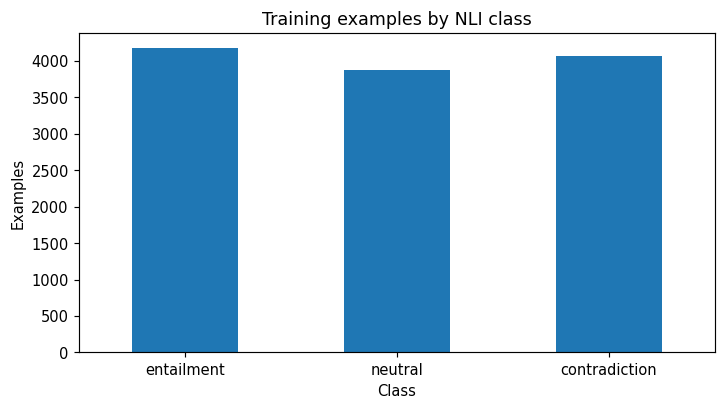

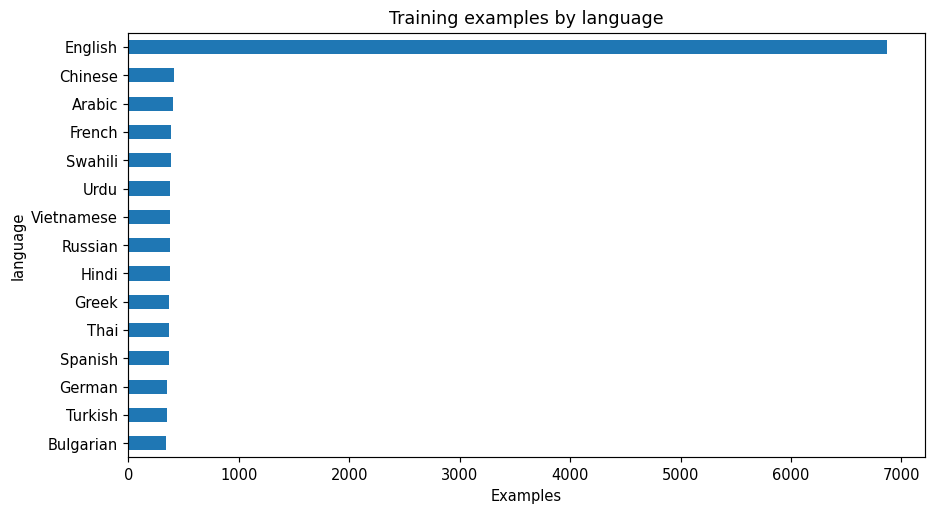

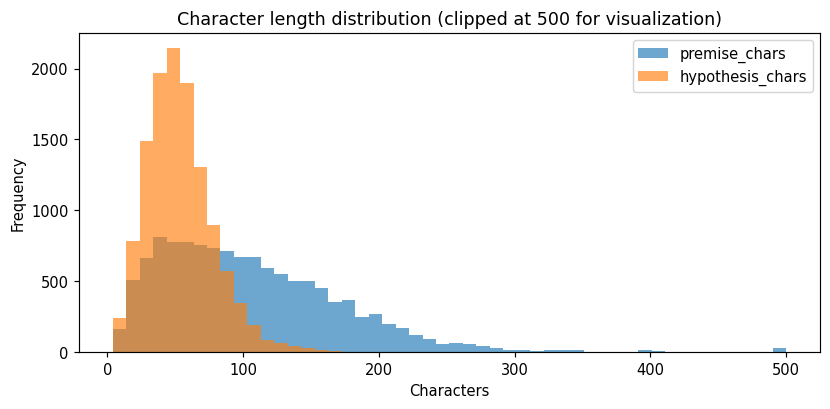

,premise_chars,hypothesis_chars
label,,
entailment,96.0,49.0
neutral,95.0,55.0
contradiction,96.0,48.0


label,entailment,neutral,contradiction
language,,,
Arabic,124,129,148
Bulgarian,123,111,108
Chinese,140,146,125
English,2427,2166,2277
French,133,129,128
German,108,116,127
Greek,120,127,125
Hindi,125,112,137
Russian,132,124,120


In [4]:
eda = train_raw.copy()
eda['premise_chars'] = eda['premise'].fillna('').astype(str).str.len()
eda['hypothesis_chars'] = eda['hypothesis'].fillna('').astype(str).str.len()
eda['premise_words'] = eda['premise'].fillna('').astype(str).str.split().str.len()
eda['hypothesis_words'] = eda['hypothesis'].fillna('').astype(str).str.split().str.len()

label_counts = eda.label.map(LABEL_NAMES).value_counts()
language_counts = eda.language.value_counts()
print('Train examples:', len(eda))
print('Train languages:', eda.language.nunique())
print('Missing cells:', int(eda[list(expected_train)].isna().sum().sum()))
print('Exact duplicate rows:', int(train_raw.duplicated().sum()))
print('Duplicate (premise,hypothesis) pairs:', int(train_raw.duplicated(['premise','hypothesis']).sum()))
print('Repeated original premise rows:', int(train_raw.premise.duplicated().sum()))
print('Text length summary:')
display(eda[['premise_chars','hypothesis_chars','premise_words','hypothesis_words']].describe().round(2))

plt.figure(figsize=(7,4))
label_counts.reindex(['entailment','neutral','contradiction']).plot(kind='bar')
plt.title('Training examples by NLI class'); plt.ylabel('Examples'); plt.xlabel('Class')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

plt.figure(figsize=(9,5))
language_counts.sort_values().plot(kind='barh')
plt.title('Training examples by language'); plt.xlabel('Examples'); plt.tight_layout(); plt.show()

eda[['premise_chars','hypothesis_chars']].clip(upper=500).plot.hist(bins=50,alpha=.65,figsize=(8,4))
plt.title('Character length distribution (clipped at 500 for visualization)')
plt.xlabel('Characters'); plt.tight_layout(); plt.show()

print('Median character lengths by class:')
display(eda.groupby('label')[['premise_chars','hypothesis_chars']].median().rename(index=LABEL_NAMES))

counts_by_lang_label = pd.crosstab(train_raw.language,train_raw.label).rename(columns=LABEL_NAMES)
counts_by_lang_label.to_csv(OUTPUT_DIR/'language_label_counts.csv')
display(counts_by_lang_label)

## 4. Clean the text
I used Unicode NFKC and collapsed extra spaces. Keep the premise and hypothesis in separate columns. We need punctuation, word order and small words like “not” because they can change the label.

The raw columns stay in the output so we can pull up the original sentences when we discuss model errors.

In [5]:
def clean_text(value):
    normalized = unicodedata.normalize('NFKC', value)
    return ' '.join(normalized.split())

def premise_group_key(value):
    # Ignore case for grouping only. Keep it in the text used for features.
    return value.casefold()

train = train_raw.copy()
test = test_raw.copy()
for frame in (train,test):
    frame['premise_clean'] = frame['premise'].map(clean_text)
    frame['hypothesis_clean'] = frame['hypothesis'].map(clean_text)
    for column in ('premise_clean', 'hypothesis_clean'):
        assert frame[column].str.len().gt(0).all(), f'Blank text in {column}'
    frame['premise_group'] = frame['premise_clean'].map(premise_group_key)
    frame['premise_len'] = frame['premise_clean'].str.len()
    frame['hypothesis_len'] = frame['hypothesis_clean'].str.len()

assert len(train)==len(train_raw) and len(test)==len(test_raw)
assert (train.loc[train['premise'].str.contains(r'\bnot\b',case=False,na=False),
                  'premise_clean'].str.contains(r'\bnot\b',case=False)).all(), 'Negation lost!'

print('Example cleaned pair:')
display(train[['premise_clean','hypothesis_clean','language','label']].head(3))
print('Normalized premise groups:', train.premise_group.nunique())
print('Premise groups repeated:', int((train.premise_group.value_counts()>1).sum()))
print('Rows in repeated groups:', int(train.premise_group.value_counts().loc[lambda v:v>1].sum()))
print('Shared premises between official train and test:',len(set(train.premise_group)&set(test.premise_group)))

Example cleaned pair:
Normalized premise groups: 8209
Premise groups repeated: 2800
Rows in repeated groups: 6711
Shared premises between official train and test: 2244


,premise_clean,hypothesis_clean,language,label
0,and these comments were considered in formulating the interim rules.,The rules developed in the interim were put together with these comments in mind.,English,0
1,"These are issues that we wrestle with in practice groups of law firms, she said.",Practice groups are not permitted to work on these issues.,English,2
2,Des petites choses comme celles-là font une différence énorme dans ce que j'essaye de faire.,J'essayais d'accomplir quelque chose.,French,0


## 5. Split by premise
I found 6,711 training rows whose premise appears more than once after normalization. Their hypotheses can differ, so I kept the rows and put each premise group on one side of the split.

Use the IDs in `split_manifest.csv` if you're working in your own notebook. The split targets 20% of premise groups, which is why the row counts are 9,667 and 2,453. Check the class and language counts below before comparing results.

In [6]:
# Use the same seed and input order to reproduce the team's manifest.
splitter = GroupShuffleSplit(n_splits=1, test_size=VALIDATION_FRACTION, random_state=SEED)
idx_train, idx_valid = next(splitter.split(train, y=train.label, groups=train.premise_group))
train_part = train.iloc[idx_train].copy().reset_index(drop=True)
valid_part = train.iloc[idx_valid].copy().reset_index(drop=True)
assert set(train_part.premise_group).isdisjoint(valid_part.premise_group)
assert set(train_part.id).isdisjoint(valid_part.id)
assert len(train_part)+len(valid_part)==len(train)

manifest = pd.concat([train_part[['id']].assign(split='train'),
                      valid_part[['id']].assign(split='validation')],ignore_index=True)
manifest.to_csv(OUTPUT_DIR/'split_manifest.csv',index=False)
print('Training:', len(train_part), 'Validation:', len(valid_part))
print('Premise overlap between partitions: 0 (verified)')
print('Class balance (proportions):')
display(pd.DataFrame({'train':train_part.label.value_counts(normalize=True).sort_index(),
                      'validation':valid_part.label.value_counts(normalize=True).sort_index()}).rename(index=LABEL_NAMES).round(3))
print('Examples per language and split:')
display(pd.crosstab(train.language, train.id.map(manifest.set_index('id').split))
        .reindex(columns=['train', 'validation'], fill_value=0))

Training: 9667 Validation: 2453
Premise overlap between partitions: 0 (verified)
Class balance (proportions):
Examples per language and split:


,train,validation
label,,
entailment,0.343,0.349
neutral,0.321,0.318
contradiction,0.336,0.333


id,train,validation
language,,
Arabic,314,87
Bulgarian,262,80
Chinese,339,72
English,5471,1399
French,302,88
German,276,75
Greek,309,63
Hindi,309,65
Russian,304,72


## 6. Check a sample for similar premises
I sampled 200 validation rows with seed 42. For each one, the table gives the closest training premise by character TF-IDF cosine similarity. Use the IDs to inspect matches at 0.95 or above. This check covers the sampled rows.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
sample_valid = valid_part.sample(n=min(200,len(valid_part)),random_state=SEED).reset_index(drop=True)
near_vect = TfidfVectorizer(analyzer='char',ngram_range=(3,5),min_df=2,max_features=15000)
X_near_train = near_vect.fit_transform(train_part.premise_clean)
X_near_valid = near_vect.transform(sample_valid.premise_clean)
# Compare each sampled validation premise with the training premises.
near_sim = cosine_similarity(X_near_valid,X_near_train)
closest = near_sim.argmax(axis=1)
max_similarity = near_sim.max(axis=1)
flags = pd.DataFrame({'validation_id':sample_valid.id,
                      'max_train_premise_similarity':max_similarity,
                      'train_id':train_part.iloc[closest].id.to_numpy()})
flags = flags.sort_values('max_train_premise_similarity',ascending=False)
flags.to_csv(OUTPUT_DIR/'near_duplicate_audit_sample.csv',index=False)
near_duplicate_count = int(flags.max_train_premise_similarity.ge(0.95).sum())
print(f'Similarity ≥ 0.95: {near_duplicate_count} of {len(flags)} sampled validation rows')
display(flags.head(10))

Similarity ≥ 0.95: 1 of 200 sampled validation rows


,validation_id,max_train_premise_similarity,train_id
159,2fe65c0837,1.000000,905b30a9ed
53,aeaa27733b,0.864481,31d8049184
143,7cbc3d1337,0.763267,a4f7d5fd88
95,3f1de93d77,0.702224,f1c67788b8
69,0844b2fe39,0.691695,a34281ab18
46,9c03ff9c62,0.682498,5ff3e3ec22
11,cbfe6ad917,0.666433,9a88f7c844
124,4f08015014,0.657324,2c812bee02
23,864dc32aa6,0.634244,5b24560b16
134,cca57a54ab,0.629224,41f5f556a4


## 7. Export the data for the team
`meeting_outputs.zip` includes the cleaned train, validation and test CSVs, the split IDs, the language/class counts and the audit. For Block 1, fit the TF-IDF vocabulary on `train_clean.csv` and use that same vocabulary to transform validation. Keep the split for Block 2 too.

In [8]:
summary = {
 'assignment':'UCLM Machine Learning NLI midterm 2026/2027',
 'dataset':'Official Kaggle Contradictory, My Dear Watson CSV files',
 'train_rows':len(train), 'test_rows':len(test),
 'n_languages':int(train.language.nunique()),
 'labels':{str(k):v for k,v in LABEL_NAMES.items()},
 'label_counts':{str(k):int(v) for k,v in train.label.value_counts().sort_index().items()},
 'missing_raw_train':{k:int(v) for k,v in train_raw.isna().sum().items()},
 'duplicate_full_rows':int(train_raw.duplicated().sum()),
 'duplicate_premise_hypothesis_pairs':int(train_raw.duplicated(['premise','hypothesis']).sum()),
 'distinct_normalized_premises':int(train.premise_group.nunique()),
 'train_rows_in_repeated_premise_groups':int(train.premise_group.value_counts()[lambda s:s>1].sum()),
 'overlapping_normalized_train_test_premises':int(len(set(train.premise_group)&set(test.premise_group))),
 'split_strategy':'GroupShuffleSplit by normalized premise, random_state=42, target validation 20%',
 'split_train_rows':len(train_part), 'split_validation_rows':len(valid_part),
 'premise_group_overlap_between_split':int(len(set(train_part.premise_group)&set(valid_part.premise_group))),
 'near_duplicate_check':'Sample of at most 200 validation premises; character TF-IDF fit on training only',
 'preprocessing':'Unicode NFKC + collapse whitespace; negation and premise/hypothesis roles preserved',
 'near_duplicate_sample_size':len(flags),
 'near_duplicate_threshold':0.95,
 'near_duplicate_candidates':near_duplicate_count,
 'missing_raw_test':{k:int(v) for k,v in test_raw.isna().sum().items()},
}
(OUTPUT_DIR/'preprocessing_summary.json').write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8'
)

for name, frame in [('train', train_part), ('validation', valid_part), ('test', test)]:
    frame.to_csv(OUTPUT_DIR / f'{name}_clean.csv', index=False)

brief = f'''# Group 05 — Notes from Hamdi

I ran this on the original competition ZIP. It has {len(train):,} labeled pairs across {train.language.nunique()} languages and {len(test):,} test pairs. The label counts are {summary["label_counts"]["0"]:,} entailment, {summary["label_counts"]["1"]:,} neutral and {summary["label_counts"]["2"]:,} contradiction. The train and test CSVs had no missing values. The labeled data had {summary["duplicate_premise_hypothesis_pairs"]} exact duplicate pairs.

Please use the split in this ZIP. It gives us {len(train_part):,} training and {len(valid_part):,} validation rows, with zero shared normalized premises. The official train and test CSVs share {summary["overlapping_normalized_train_test_premises"]:,} normalized premise texts. For our model comparisons, use the local validation split.

The similarity audit flagged {near_duplicate_count} of {len(flags)} sampled validation rows at 0.95 or above. The CSV has both IDs so we can look up the original sentences.

For Block 1, fit the vectorizers on training and bring your validation scores and a couple of real mistakes to discuss. The POS code in the starter only covers English. For Block 2, reuse this split and compare the same classifier with and without the BERTopic features.
'''
(OUTPUT_DIR/'Group05_Meeting_Brief.md').write_text(brief, encoding='utf-8')

meeting_files = [
    'split_manifest.csv', 'preprocessing_summary.json', 'language_label_counts.csv',
    'near_duplicate_audit_sample.csv', 'Group05_Meeting_Brief.md',
    'train_clean.csv', 'validation_clean.csv', 'test_clean.csv',
]
with zipfile.ZipFile(OUTPUT_DIR/'meeting_outputs.zip', 'w', compression=zipfile.ZIP_DEFLATED) as z:
    for name in meeting_files:
        z.write(OUTPUT_DIR/name, arcname=name)
print('Saved:', OUTPUT_DIR/'meeting_outputs.zip')

Saved: /workspace/scratch/3752cb880e55/nli_outputs/meeting_outputs.zip


## Block 1 starter
Set `RUN_BLOCK1_BASELINES = True` to try Naive Bayes and Random Forest on this split. Each text gets its own character TF-IDF vector. The POS counts come from an English tagger, so those columns are zero for the other languages. Keep that limitation in mind when you compare scores by language.

In [9]:
if RUN_BLOCK1_BASELINES:
    import nltk
    # The pretrained tagger is downloaded in a connected Colab/Kaggle session.
    tagger = 'averaged_perceptron_tagger_eng'
    try:
        nltk.data.find(f'taggers/{tagger}')
    except LookupError:
        nltk.download(tagger, quiet=True, raise_on_error=True)
    from functools import lru_cache
    from scipy.sparse import csr_matrix, hstack
    from sklearn.naive_bayes import MultinomialNB
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
    from sklearn.feature_extraction.text import TfidfVectorizer
    from time import perf_counter

    @lru_cache(maxsize=50000)
    def english_pos_counts(text):
        """Counts of actual NLTK Penn-Treebank POS tags, English text ONLY."""
        tokens = re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?|\d+(?:[.,]\d+)*", text)
        counts = np.zeros(7, dtype=np.float32)
        if not tokens:
            return counts
        tags = nltk.pos_tag(tokens)
        for _, tag in tags:
            if tag.startswith('NN'): counts[0] += 1
            elif tag.startswith('VB'): counts[1] += 1
            elif tag.startswith('JJ'): counts[2] += 1
            elif tag.startswith('RB'): counts[3] += 1
            elif tag.startswith('PRP'): counts[4] += 1
            elif tag.startswith('CD'): counts[5] += 1
            else: counts[6] += 1
        return counts / len(tokens)

    def make_pos_matrix(frame):
        rows=[]
        for row in frame.itertuples(index=False):
            if row.language == 'English':
                p = english_pos_counts(row.premise_clean)
                h = english_pos_counts(row.hypothesis_clean)
            else:
                p = np.zeros(7,dtype=np.float32)
                h = np.zeros(7,dtype=np.float32)
            rows.append(np.concatenate([p,h]))
        return csr_matrix(np.asarray(rows,dtype=np.float32))

    def fit_char_features(training_df, validation_df):
        # Fit one vocabulary per text role on training.
        vt = dict(analyzer='char',ngram_range=(3,5),min_df=2,
                  max_features=MAX_CHAR_FEATURES,sublinear_tf=True,dtype=np.float32)
        vp = TfidfVectorizer(**vt)
        vh = TfidfVectorizer(**vt)
        tp = vp.fit_transform(training_df.premise_clean)
        th = vh.fit_transform(training_df.hypothesis_clean)
        ap = vp.transform(validation_df.premise_clean)
        ah = vh.transform(validation_df.hypothesis_clean)
        return vp,vh, hstack([tp,th,make_pos_matrix(training_df)],format='csr'), hstack([ap,ah,make_pos_matrix(validation_df)],format='csr')

    start_features=perf_counter()
    vp,vh,Xtr,Xva = fit_char_features(train_part,valid_part)
    print('Training features:',Xtr.shape,'Validation features:',Xva.shape,'Features seconds:',round(perf_counter()-start_features,1))
else:
    print('Block 1 training is off.')

Block 1 training is off.


In [10]:
if RUN_BLOCK1_BASELINES:
    candidates = {
        'MultinomialNB': MultinomialNB(alpha=0.5),
        'RandomForest': RandomForestClassifier(n_estimators=80,max_depth=24,
                                                min_samples_leaf=2,n_jobs=-1,
                                                random_state=SEED,class_weight='balanced_subsample')
    }
    results=[]
    trained={}
    for name,model in candidates.items():
        started=perf_counter()
        model.fit(Xtr,train_part.label)
        pred = model.predict(Xva)
        elapsed=perf_counter()-started
        acc=accuracy_score(valid_part.label,pred)
        mf1=f1_score(valid_part.label,pred,average='macro')
        results.append(dict(algorithm=name,accuracy=acc,macro_f1=mf1,train_predict_seconds=elapsed,
                            features='Separate premise/hypothesis char TF-IDF + English-only POS tags'))
        trained[name]=model
        print(' ',name,'accuracy:',round(acc,4),'macro-F1:',round(mf1,4),'seconds:',round(elapsed,1))
        print(classification_report(valid_part.label,pred,labels=[0,1,2],target_names=list(LABEL_NAMES.values()),zero_division=0))
        ConfusionMatrixDisplay.from_predictions(valid_part.label,pred,labels=[0,1,2],
                                                 display_labels=list(LABEL_NAMES.values()),cmap='Greys')
        plt.title('Validation confusion matrix: '+name)
        plt.tight_layout();plt.show()
        lang_report = valid_part[['language','label']].copy()
        lang_report['correct'] = (valid_part.label.to_numpy()==pred)
        print('Validation accuracy by language (counts matter):')
        display(lang_report.groupby('language').correct.agg(['count','mean']).rename(columns={'mean':'accuracy'}).sort_values('count',ascending=False).round(3))
    results_df=pd.DataFrame(results).sort_values(['accuracy','macro_f1'],ascending=False)
    results_df.to_csv(OUTPUT_DIR/'baseline_results.csv',index=False)
    display(results_df)
    chosen_name=str(results_df.iloc[0]['algorithm'])
    print('Candidate selected by HELD-OUT VALIDATION accuracy:',chosen_name)
else:
    print('Skipping model comparison until RUN_BLOCK1_BASELINES=True.')

Skipping model comparison until RUN_BLOCK1_BASELINES=True.


## Optional submission CSV
When we've picked a model using validation accuracy, enable `MAKE_SUBMISSION_IF_BASELINES` to refit on all labeled rows and predict in template ID order. Generate the submission in a Kaggle notebook for the competition.

In [11]:
if RUN_BLOCK1_BASELINES and MAKE_SUBMISSION_IF_BASELINES:
    from sklearn.base import clone
    start_full=perf_counter()
    vp_full,vh_full,Xfull,Xtest = fit_char_features(train,test)
    final_model=clone(candidates[chosen_name])
    final_model.fit(Xfull,train.label)
    predictions=final_model.predict(Xtest).astype(int)
    submission=sample_submission[['id']].merge(
        pd.DataFrame({'id':test.id,'prediction':predictions}),on='id',how='left',validate='one_to_one')
    assert len(submission)==len(test)==5195
    assert not submission.prediction.isna().any()
    submission['prediction']=submission['prediction'].astype(int)
    assert set(submission.prediction.unique()) <= {0,1,2}
    submission.to_csv(OUTPUT_DIR/'submission.csv',index=False)
    print('Final model:',chosen_name)
    print('Saved:',OUTPUT_DIR/'submission.csv', 'shape:',submission.shape)
    print('Refit + prediction seconds:',round(perf_counter()-start_full,1))
    display(submission.head())
    if not IS_KAGGLE:
        print('WARNING: This is a local draft. Kaggle requires generating submission.csv from a Kaggle Notebook.')
else:
    print('No submission produced in preprocessing-only mode.')

No submission produced in preprocessing-only mode.


## For our next meeting
Bring the validation accuracy, macro-F1, per-class precision and recall, confusion matrix, and a few misclassified pairs from each model. Record the runtime and settings so we can rerun the comparison.

For Block 2, compare two BERTopic clusterers. Keep the classifier and validation IDs fixed for the with/without-topic comparison, and report per-class ROC/AUROC.

Both blocks are due on Virtual Campus before 23:59 Madrid time on December 13, 2026. The defense is December 14–15.